# 04 Payoff and ADUs by 2031

Logic: `pipeline/tract/payoff.py`, `forecast.py`, `migration.py`, `rollup.py`, `viz.py`. Every number they use is in `shared/assumptions.json` (keys starting with `tract.` plus the two mortgage rates).

**Outputs the tool reads**: `payoff_tract.csv`, `forecast_town.csv`, `county_rollup.csv`. Extra tables go to `processed/5500/`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 60   # keeps the notebook small. Saved figures use 120 dpi

from pipeline.tract import forecast, migration, payoff, plots, rollup, viz

## 1. Does a 600 sq ft unit pay off?

- Cost: 600 sq ft x $175 / $250 / $300 per sq ft + 15% soft costs, all borrowed over 30 years
- Rate: 6.53% (2026 average of weekly PMMS) in the main run. 7.18% (latest week) in the sensitivity table
- Rent: a 600 sq ft unit is a 1-bedroom, so the test uses a 1-bedroom rent (`rent_b1`, the same column the tool uses)
- Net rent = rent x (1 - 30%). yes = covers the mid payment. maybe = covers the low payment or is within 10% of the mid one

In [2]:
p = payoff.run()
pd.Series(p['summary']).drop(['count', 'build_cost', 'monthly_payment', 'breakeven_rent', 'pop_share'])

rent_basis              rent_b1
rate                      0.065
rate_now                  0.072
tracts_with_rent           3445
tracts                     3445
share_yes                 0.103
share_maybe                0.26
share_no                  0.636
share_yes_all_units       0.203
share_yes_safmr           0.165
share_yes_rate_now        0.073
safmr_tract_coverage        1.0
dtype: object

In [3]:
pd.DataFrame({'build cost': p['summary']['build_cost'], 'monthly payment': p['summary']['monthly_payment'],
              'rent needed': p['summary']['breakeven_rent']}).round(0)

,build cost,monthly payment,rent needed
low,120750.0,766.0,1094.0
mid,172500.0,1094.0,1562.0
high,207000.0,1312.0,1875.0


### Rent bases compared

- `rent_b1`: tract median rent x the county ratio of 1-bedroom to all-unit rent (B25031). Every tract has one
- `rent_b1_tract`: the raw tract 1-bedroom median. Blank in 1 tract of 3 and noisy
- `safmr_1br`: HUD Small Area FMR, FY2026, by ZIP, averaged over each tract's ZIPs. It is the 40th percentile of recent movers, so it runs higher than ACS medians, which include long-time tenants
- `median_rent_all`: all units, the basis of the first report

In [4]:
p['basis_summary'].round(3)

,rent_basis,label,tracts,median,median_ratio_to_headline,corr_with_headline
0,rent_b1,"1-bedroom, tract median x county B25031 ratio ...",3445,956.00,1.000,1.000
1,rent_b1_tract,"1-bedroom, raw tract B25031 median",2146,906.00,1.036,0.879
2,safmr_1br,"1-bedroom, HUD SAFMR FY2026 by ZIP",3445,1178.01,1.249,0.780
3,median_rent_all,"All units, tract median B25064 (first report)",3261,1149.00,1.216,0.988


### Sensitivity: share of tracts that pay (yes), by rent basis, rate and cost

In [5]:
sens = p['sensitivity']
(sens.pivot_table(index=['rent_basis', 'rate_name'], columns='cost_level', values='share_yes')[['low', 'mid', 'high']] * 100).round(1)

cost_level                     low   mid  high
rent_basis      rate_name                     
median_rent_all 2026 average  55.9  20.3   9.2
                latest week   48.1  15.8   6.8
rent_b1         2026 average  36.4  10.3   4.0
                latest week   30.6   7.3   2.8
rent_b1_tract   2026 average  33.7  11.8   4.3
                latest week   27.7   9.0   3.4
safmr_1br       2026 average  60.8  16.5   6.6
                latest week   50.8  11.7   4.1

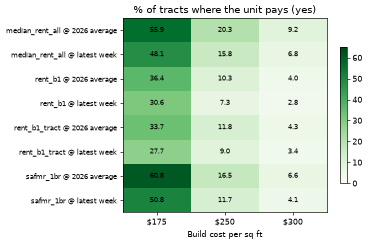

In [6]:
plots.sensitivity_heat(sens);

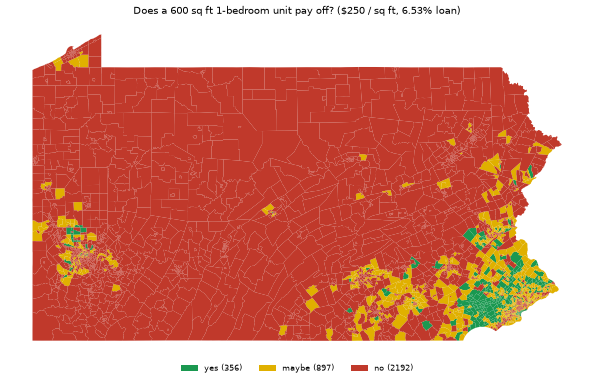

In [7]:
s = p['summary']
plots.payoff_map(p['payoff'], f"Does a 600 sq ft 1-bedroom unit pay off? ($250 / sq ft, {s['rate']:.2%} loan)");

### Counties with the most tracts that pay

In [8]:
payoff.county_table(p['payoff']).sort_values('yes', ascending=False).head(10).round(3)

,county,tracts,yes,maybe,median_rent_b1,share_yes,share_yes_or_maybe
45,42091,219,76,116,1467.0,0.347,0.877
50,42101,408,73,207,1242.0,0.179,0.686
14,42029,124,67,43,1604.0,0.540,0.887
8,42017,147,48,79,1375.0,0.327,0.864
22,42045,152,29,77,1176.0,0.191,0.697
1,42003,394,22,89,965.0,0.056,0.282
38,42077,81,13,31,1137.0,0.160,0.543
35,42071,116,7,51,1093.0,0.060,0.500
47,42095,74,7,36,1123.5,0.095,0.581
44,42089,51,2,16,982.0,0.039,0.353


## 2. Where did housing grow? Model and validation

- Target: log(decennial homes 2020 / 2010) per tract. Tracts with under 100 homes in 2010 are left out
- Features: 2010 values only. IRS county migration is tested as an extra feature
- Models: state median (baseline), ridge, random forest, gradient boosting (absolute-error loss)
- Spatial cross-validation: whole counties held out, and 40 km grid blocks held out. Random 5-fold is shown only to show how much it flatters
- Rule: the model with the lowest county-held-out MAE is used. R2 is shown too, but a few crosswalk artifacts dominate it

In [9]:
f = forecast.run()
{k: v for k, v in f['summary'].items() if k != 'totals'}

{'model': 'gradient_boosting',
 'use_migration': False,
 'migration_gain_r2': 0.006407986391154696,
 'training_tracts': 3394,
 'target_median_growth': 0.013136399797402092,
 'conformal_halfwidth_log': 0.20395700032514597,
 'conformal_coverage_mean': 0.8983758532574428,
 'conformal_coverage_min': 0.8455882352941176,
 'quantile_gb': {'coverage': 0.7613435474366529,
  'median_width': 0.1704560037064319},
 'top4': ['log_units', 'log_workers', 'units_per_km2', 'dev_share'],
 'pa_pop_2024': 13018639.0}

In [10]:
f['cv'].round(3)

,scheme,model,r2_pooled,mae,r2_fold_mean
0,random_5fold,median_baseline,-0.002,0.107,NaN
1,random_5fold,ridge,0.191,0.115,NaN
2,random_5fold,random_forest,0.225,0.093,NaN
3,random_5fold,gradient_boosting,0.164,0.088,NaN
4,county_blocks,median_baseline,-0.003,0.107,-0.008
5,county_blocks,ridge,0.194,0.120,0.214
6,county_blocks,random_forest,0.216,0.100,0.202
7,county_blocks,gradient_boosting,0.202,0.092,0.256
8,grid_40km_blocks,median_baseline,-0.002,0.107,-0.007
9,grid_40km_blocks,ridge,0.197,0.116,0.205


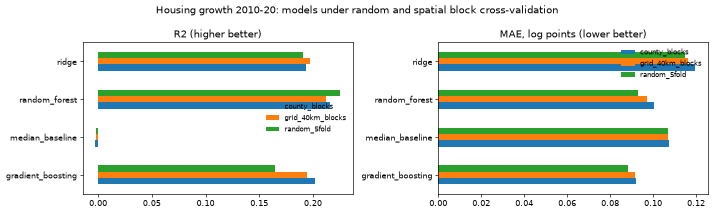

In [11]:
plots.model_compare(f['cv']);

### Temporal backtest

- Train on the change from 2010-14 to 2015-19 (ACS homes, features at 2010-14). Predict the change from 2015-19 to 2020-24 (features at 2015-19). Score against what the 2020-24 ACS reports
- Baselines: each tract keeps its own earlier change (last-period rate), and the earlier median
- `beyond_moe` columns score only tracts whose change is bigger than its ACS margin of error

In [12]:
f['backtest'].round(3)

,model,r2,mae,corr,r2_beyond_moe,corr_beyond_moe,tracts_beyond_moe
0,median_of_earlier_period,-0.002,0.120,-0.000,-0.009,0.000,958
1,last_period_rate,-0.086,0.133,0.005,-0.043,0.013,958
2,ridge,0.025,0.117,0.194,0.020,0.230,958
3,random_forest,0.019,0.118,0.140,0.019,0.173,958
4,gradient_boosting,0.021,0.118,0.152,0.020,0.197,958


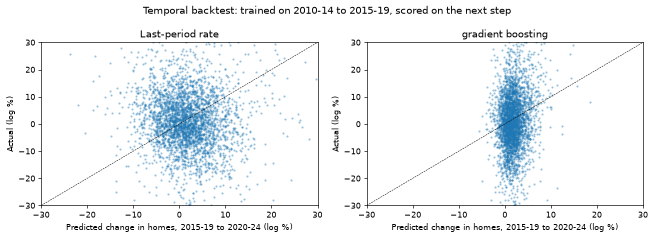

In [13]:
plots.backtest_scatter(f['backtest_detail'], f['summary']['model']);

### Prediction intervals

- Split conformal, 90%: half-width = a high quantile of the absolute county-held-out errors
- Coverage is checked fold by fold, with the half-width taken from the other folds only

In [14]:
f['coverage'].round(3)

,fold,halfwidth,coverage,n
0,0,0.187,0.846,680
1,1,0.215,0.926,679
2,2,0.221,0.947,679
3,3,0.189,0.857,679
4,4,0.210,0.916,677


### Permutation importance on held-out counties, and partial dependence for the top 4

In [15]:
f['importance'].round(4)

,importance,fold_sd
log_units,0.691,0.364
log_workers,0.522,0.231
units_per_km2,0.041,0.009
dev_share,0.028,0.022
x,0.012,0.005
y,0.007,0.006
log_jobs,0.006,0.004
devhi_share,0.003,0.005
jobs_per_unit,0.002,0.017
log_area,0.002,0.007


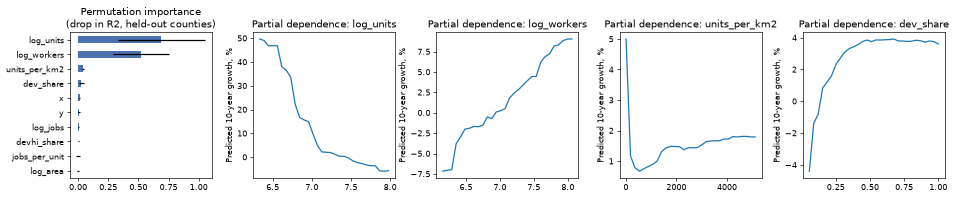

In [16]:
plots.importance_pdp(f['importance'], f['pdp']);

### IRS migration

- County net movers per 1,000 residents, before (2012-19) and after (2020-23)
- As a model feature it did not clear the bar (see `migration_gain_r2` above). It stays as context

In [17]:
panel = pd.read_csv(ROOT / 'data/processed/tract_panel.csv', dtype={'GEOID': str, 'county': str})
mig = migration.periods(migration.load(), panel)
mig.describe().round(2)

,before,after,change
count,67.00,67.00,67.00
mean,-1.10,1.61,2.71
std,2.78,4.27,3.13
min,-8.26,-14.81,-6.55
25%,-2.70,-0.40,0.99
50%,-1.30,1.12,2.55
75%,0.38,3.26,3.89
max,5.56,18.34,15.58


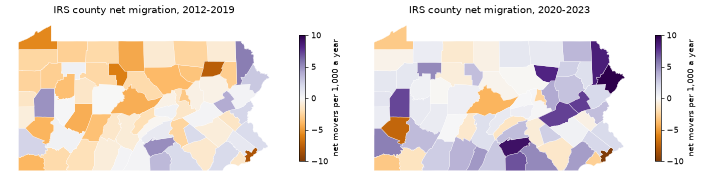

In [18]:
plots.migration_map(mig);

## 3. ADUs by 2031

- ADUs = people x permit rate x payoff weight x lots index x demand x town rule x 5 years, capped at lots with room
- Permit rate 26 / 53.5 / 81 per 100,000 people a year (low / mid / high). Rule factor for limited towns 0.02 / 0.05 / 0.10
- Today: rules from `shared/legal_status.csv` (12 towns coded). Unlisted towns count as limited
- HB 2186: every town allowed. SB 1346: every town allowed except Philadelphia and Pittsburgh (the MPC does not reach them)
- Both bills die on Nov 30, 2026 if not enacted
- This is scenario arithmetic, not a fitted model. Pennsylvania has no ADU permit series: the Census permit survey does not split out ADUs, and Philadelphia has about 10 legal ADUs since 2012. So the low-high range shows the assumptions, not statistical error

In [19]:
f['totals'].round(1)

by_2031                   per_year                 per_100k_per_year            
            low      mid     high      low     mid    high               low   mid  high
rule                                                                                    
current   247.9    896.3   2332.1     49.6   179.3   466.4               0.4   1.4   3.6
hb2186   6388.7  13144.4  19898.4   1277.7  2628.9  3979.7               9.8  20.2  30.6
sb1346   6235.7  12839.3  19460.6   1247.1  2567.9  3892.1               9.6  19.7  29.9

Mid ADUs by 2031 by the town's rule today and whether it is coded

In [20]:
f['by_rule']

rule                current   hb2186   sb1346
adu_rule coded                               
allowed  coded        252.0    252.0    252.0
limited  coded         23.0    458.0    153.0
         not coded    622.0  12435.0  12435.0

In [21]:
t = f['towns']
t[t.town_geoid.isin([forecast.PHILADELPHIA, forecast.PITTSBURGH])][['name', 'rule', 'adus_low', 'adus_mid', 'adus_high']]

,name,rule,adus_low,adus_mid,adus_high
366,Pittsburgh city,current,81.1,166.2,250.6
367,Pittsburgh city,hb2186,81.1,166.2,250.6
368,Pittsburgh city,sb1346,81.1,166.2,250.6
5913,Philadelphia city,current,3.1,16.1,48.6
5914,Philadelphia city,hb2186,156.1,321.2,486.4
5915,Philadelphia city,sb1346,3.1,16.1,48.6


In [22]:
t[t.rule == 'hb2186'].nlargest(10, 'adus_mid')[['name', 'rule_today', 'pop', 'adus_low', 'adus_mid', 'adus_high']].round(0)

,name,rule_today,pop,adus_low,adus_mid,adus_high
5914,Philadelphia city,limited,1.580e+06,156.0,321.0,486.0
367,Pittsburgh city,allowed,3.048e+05,81.0,166.0,251.0
5446,Lower Merion township,limited,6.417e+04,61.0,125.0,190.0
1441,Northampton township,limited,3.992e+04,60.0,123.0,186.0
3160,Haverford township,limited,5.087e+04,54.0,112.0,170.0
3202,Radnor township,limited,3.372e+04,50.0,102.0,154.0
5383,Abington township,limited,5.866e+04,46.0,94.0,142.0
1414,Middletown township,limited,4.579e+04,44.0,92.0,139.0
1408,Lower Makefield township,limited,3.348e+04,41.0,84.0,128.0
2218,Tredyffrin township,limited,3.192e+04,40.0,82.0,124.0


In [23]:
permits = pd.read_csv(ROOT / 'data/processed/permits_county.csv')
recent = permits[permits.year >= permits.year.max() - 4].groupby('year').units_total.sum()
print(recent)
print('HB 2186 mid per year / recent average permits:', round(f['totals'].loc['hb2186', ('per_year', 'mid')] / recent.mean(), 3))

year
2021    47894
2022    28149
2023    25320
2024    24810
2025    25709
Name: units_total, dtype: int64
HB 2186 mid per year / recent average permits: 0.087


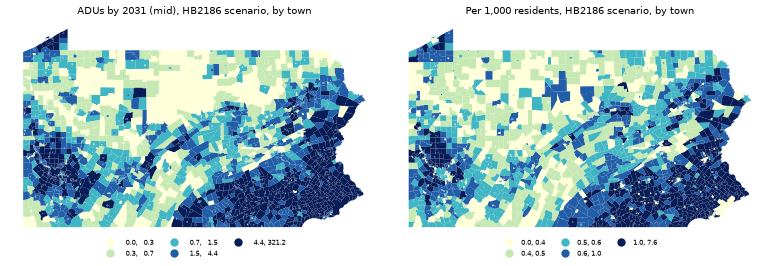

In [24]:
plots.forecast_map(f['towns']);

## 4. County roll-up and the linked view

In [25]:
c = rollup.run()
c.sort_values('adus_mid_hb2186', ascending=False)[['name', 'tracts', 'tracts_pays_yes', 'adus_mid_current', 'adus_mid_hb2186', 'adus_mid_sb1346']].head(10).round(1)

,name,tracts,tracts_pays_yes,adus_mid_current,adus_mid_hb2186,adus_mid_sb1346
45,Montgomery,219,76,80.6,1611.0,1611.0
14,Chester,124,67,96.0,1416.1,1416.1
8,Bucks,147,48,66.6,1332.5,1332.5
1,Allegheny,394,22,218.5,1212.0,1212.0
22,Delaware,152,29,38.8,775.8,775.8
35,Lancaster,116,7,33.8,675.4,675.4
38,Lehigh,81,13,73.3,511.0,511.0
66,York,108,1,25.3,505.1,505.1
47,Northampton,74,7,23.3,465.1,465.1
5,Berks,107,1,20.6,412.7,412.7


In [26]:
viz.run()

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:1177: RuntimeWarning: invalid value encountered in simplify_preserve_topology
  return lib.simplify_preserve_topology(geometry, tolerance, **kwargs)


{'html_kb': 614.0947265625, 'spec_kb': 561.736328125, 'tracts': 3445}

The linked view is `musa5500/figures/tract_explorer.html`. Click a county, then drag a box on the scatter. The bars, histogram and table follow.